<a href="https://colab.research.google.com/github/saraaldenali5555/Machine_Learning_Training/blob/main/Training_Diabetes.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [21]:
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd
file_path = '/content/drive/MyDrive/ML_Training/Dataset/diabetes_prediction_dataset.csv'

df = pd.read_csv(file_path)
df.info()
print("Dataset Shape:", df.shape)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 9 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   gender               100000 non-null  object 
 1   age                  100000 non-null  float64
 2   hypertension         100000 non-null  int64  
 3   heart_disease        100000 non-null  int64  
 4   smoking_history      100000 non-null  object 
 5   bmi                  100000 non-null  float64
 6   HbA1c_level          100000 non-null  float64
 7   blood_glucose_level  100000 non-null  int64  
 8   diabetes             100000 non-null  int64  
dtypes: float64(3), int64(4), object(2)
memory usage: 6.9+ MB
Dataset Shape: (100000, 9)


In [22]:
print("Dataset Shape:", df.shape)
print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

Dataset Shape: (100000, 9)
Number of Rows: 100000
Number of Columns: 9


In [23]:
# 1. التحقق من القيم المفقودة
missing_values = df.isnull().sum()
print("القيم المفقودة في كل عمود:")
print(missing_values)

# حذف القيم المفقودة إن وجدت
df_cleaned = df.dropna()
print(f"\nحجم البيانات بعد حذف القيم المفقودة: {df_cleaned.shape}")

# 2. التحقق من الصفوف المكررة وحذفها
duplicates_count = df_cleaned.duplicated().sum()
print(f"\nعدد الصفوف المكررة: {duplicates_count}")

df_cleaned = df_cleaned.drop_duplicates()
print(f"حجم البيانات بعد حذف القيم المكررة: {df_cleaned.shape}")

القيم المفقودة في كل عمود:
gender                 0
age                    0
hypertension           0
heart_disease          0
smoking_history        0
bmi                    0
HbA1c_level            0
blood_glucose_level    0
diabetes               0
dtype: int64

حجم البيانات بعد حذف القيم المفقودة: (100000, 9)

عدد الصفوف المكررة: 3854
حجم البيانات بعد حذف القيم المكررة: (96146, 9)


In [24]:
# تحويل المتغيرات الفئوية (Categorical) إلى رقمية باستخدام Label Encoding أو Mapping المناسب
if 'gender' in df_cleaned.columns and df_cleaned['gender'].dtype == 'object':
    df_cleaned['gender'] = df_cleaned['gender'].astype('category').cat.codes

if 'smoking_history' in df_cleaned.columns and df_cleaned['smoking_history'].dtype == 'object':
    df_cleaned['smoking_history'] = df_cleaned['smoking_history'].astype('category').cat.codes

print("تم تحويل المتغيرات الفئوية بنجاح.")
df_cleaned.info()

تم تحويل المتغيرات الفئوية بنجاح.
<class 'pandas.core.frame.DataFrame'>
Index: 96146 entries, 0 to 99999
Data columns (total 9 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   gender               96146 non-null  int8   
 1   age                  96146 non-null  float64
 2   hypertension         96146 non-null  int64  
 3   heart_disease        96146 non-null  int64  
 4   smoking_history      96146 non-null  int8   
 5   bmi                  96146 non-null  float64
 6   HbA1c_level          96146 non-null  float64
 7   blood_glucose_level  96146 non-null  int64  
 8   diabetes             96146 non-null  int64  
dtypes: float64(3), int64(4), int8(2)
memory usage: 6.1 MB


عدد الحالات لكل فئة:
diabetes
0    87664
1     8482
Name: count, dtype: int64

النسبة المئوية لكل فئة:
diabetes
0    91.178
1     8.822
Name: proportion, dtype: float64


/tmp/ipykernel_1472/281013524.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='diabetes', data=df_cleaned, palette='Set2')


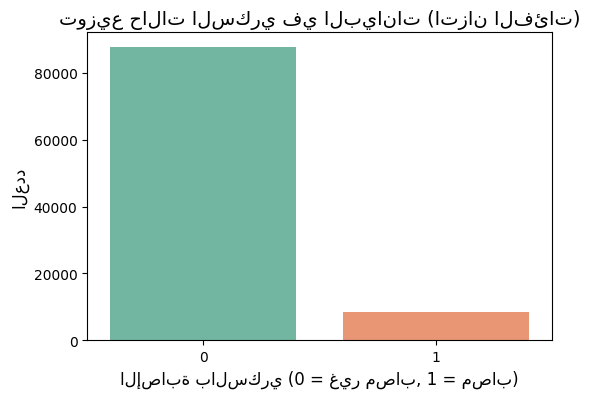

In [42]:
import matplotlib.pyplot as plt
import seaborn as sns

# حساب عدد ونسب الفئات للهدف (diabetes)
class_counts = df_cleaned['diabetes'].value_counts()
class_percentages = df_cleaned['diabetes'].value_counts(normalize=True) * 100

print("عدد الحالات لكل فئة:")
print(class_counts)
print("\nالنسبة المئوية لكل فئة:")
print(class_percentages)

# رسم توضيحي لتوزيع الفئات لتوضيح عدم الاتزان
plt.figure(figsize=(6, 4))
# استخدام الأسماء العربية في الرسم
sns.countplot(x='diabetes', data=df_cleaned, palette='Set2')
plt.title('توزيع حالات السكري في البيانات (اتزان الفئات)', fontsize=14)
plt.xlabel('الإصابة بالسكري (0 = غير مصاب, 1 = مصاب)', fontsize=12)
plt.ylabel('العدد', fontsize=12)
plt.show()

إجمالي عدد السجلات بالكامل: 96,146

عدد الحالات المصابة والسليمة الأصلي:
عدد الحالات السليمة (0): 87,664
عدد الحالات المصابة (1): 8,482

--- توزيع الفئات بعد تقليل الفئة الأغلبية على كامل البيانات ---
عدد الحالات السليمة (0) بعد التقليل: 8,482
عدد الحالات المصابة (1) بعد التقليل: 8,482


,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
87626,1,58.0,0,0,3,33.85,5.7,280,1
31420,0,32.0,0,0,4,25.82,6.0,100,0
71273,0,61.0,0,0,4,27.32,8.8,130,1
99658,0,20.0,0,0,4,27.32,6.5,159,0
17212,1,78.0,1,0,0,19.60,7.0,300,1
92428,1,34.0,0,0,2,27.32,6.2,85,0
2901,0,68.0,1,0,4,36.39,6.2,159,1
12891,0,52.0,0,0,4,27.32,5.0,100,0
77319,1,15.0,0,0,4,41.29,5.8,130,0
65431,0,33.0,0,0,4,25.10,7.5,159,1


========== K-Nearest Neighbors (KNN=5) [Balanced Data] ==========
Classification Report (تقرير الأداء):
              precision    recall  f1-score   support

           0       0.86      0.85      0.85      1697
           1       0.85      0.86      0.86      1696

    accuracy                           0.85      3393
   macro avg       0.86      0.85      0.85      3393
weighted avg       0.86      0.85      0.85      3393

Confusion Matrix (مصفوفة الارتباك):
[[1435  262]
 [ 230 1466]]


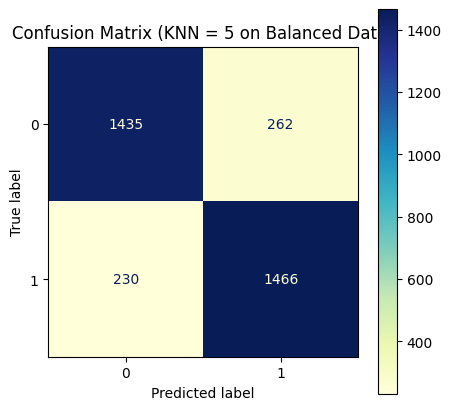

========== Naive Bayes [Balanced Data] ==========
Classification Report (تقرير الأداء):
              precision    recall  f1-score   support

           0       0.80      0.90      0.84      1697
           1       0.88      0.77      0.82      1696

    accuracy                           0.83      3393
   macro avg       0.84      0.83      0.83      3393
weighted avg       0.84      0.83      0.83      3393

Confusion Matrix (مصفوفة الارتباك):
[[1523  174]
 [ 387 1309]]


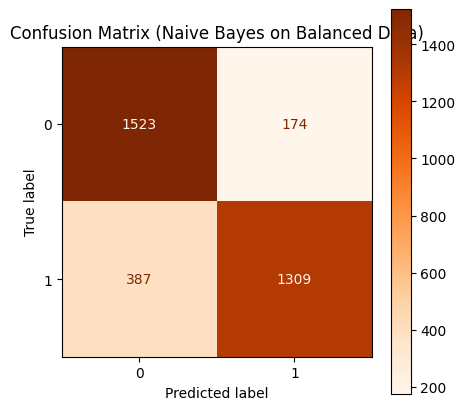

========== Decision Tree [Balanced Data] ==========
Classification Report (تقرير الأداء):
              precision    recall  f1-score   support

           0       0.91      0.89      0.90      1697
           1       0.89      0.91      0.90      1696

    accuracy                           0.90      3393
   macro avg       0.90      0.90      0.90      3393
weighted avg       0.90      0.90      0.90      3393

Confusion Matrix (مصفوفة الارتباك):
[[1510  187]
 [ 146 1550]]


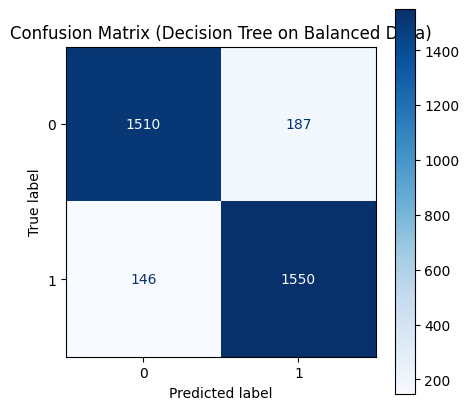

========== Random Forest [Balanced Data] ==========
Classification Report (تقرير الأداء):
              precision    recall  f1-score   support

           0       0.92      0.89      0.91      1697
           1       0.89      0.93      0.91      1696

    accuracy                           0.91      3393
   macro avg       0.91      0.91      0.91      3393
weighted avg       0.91      0.91      0.91      3393

Confusion Matrix (مصفوفة الارتباك):
[[1510  187]
 [ 125 1571]]


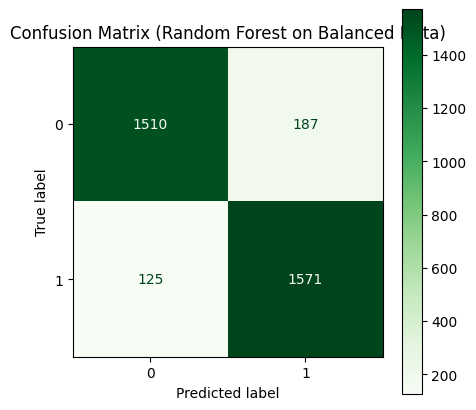

========== Random Forest [Balanced Data] ==========
Classification Report (تقرير الأداء):
              precision    recall  f1-score   support

           0       0.92      0.90      0.91      1697
           1       0.90      0.92      0.91      1696

    accuracy                           0.91      3393
   macro avg       0.91      0.91      0.91      3393
weighted avg       0.91      0.91      0.91      3393

Confusion Matrix (مصفوفة الارتباك):
[[1519  178]
 [ 133 1563]]


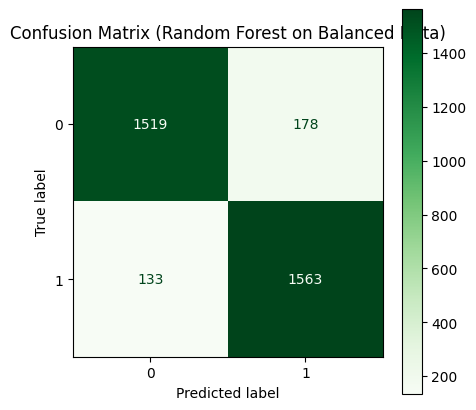

========== Logistic Regression [Balanced Data] ==========
Classification Report (تقرير الأداء):
              precision    recall  f1-score   support

           0       0.88      0.88      0.88      1697
           1       0.88      0.88      0.88      1696

    accuracy                           0.88      3393
   macro avg       0.88      0.88      0.88      3393
weighted avg       0.88      0.88      0.88      3393

Confusion Matrix (مصفوفة الارتباك):
[[1498  199]
 [ 211 1485]]


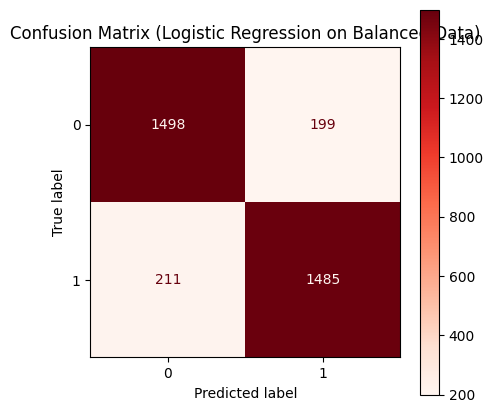

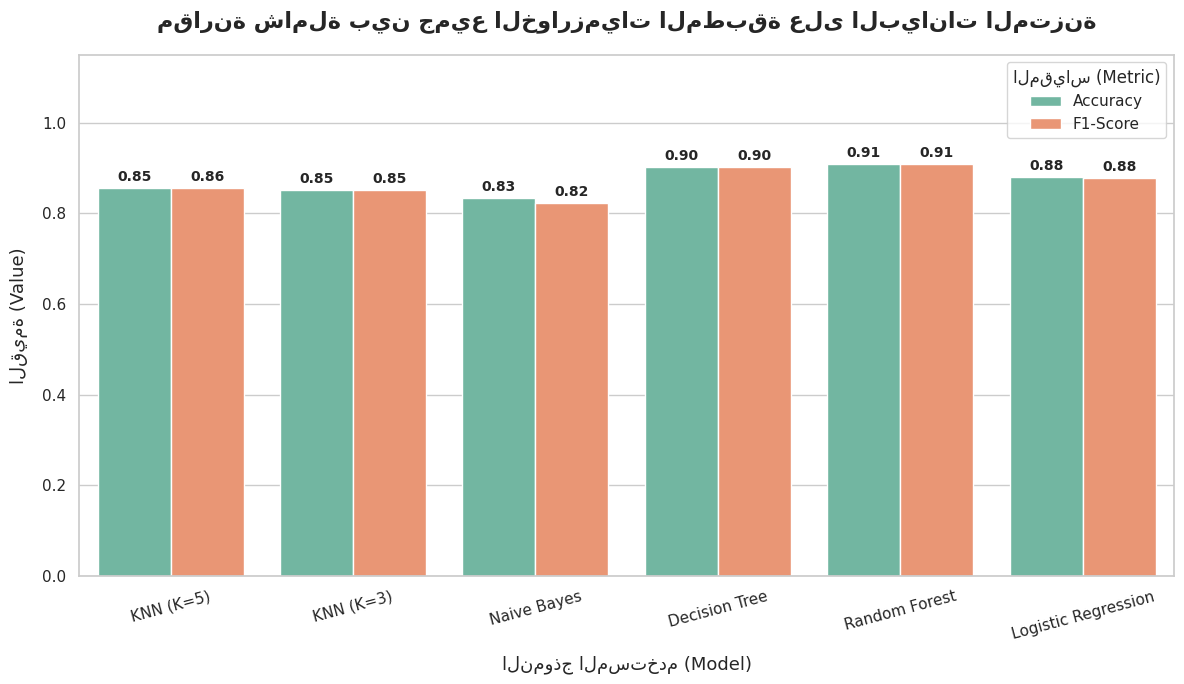

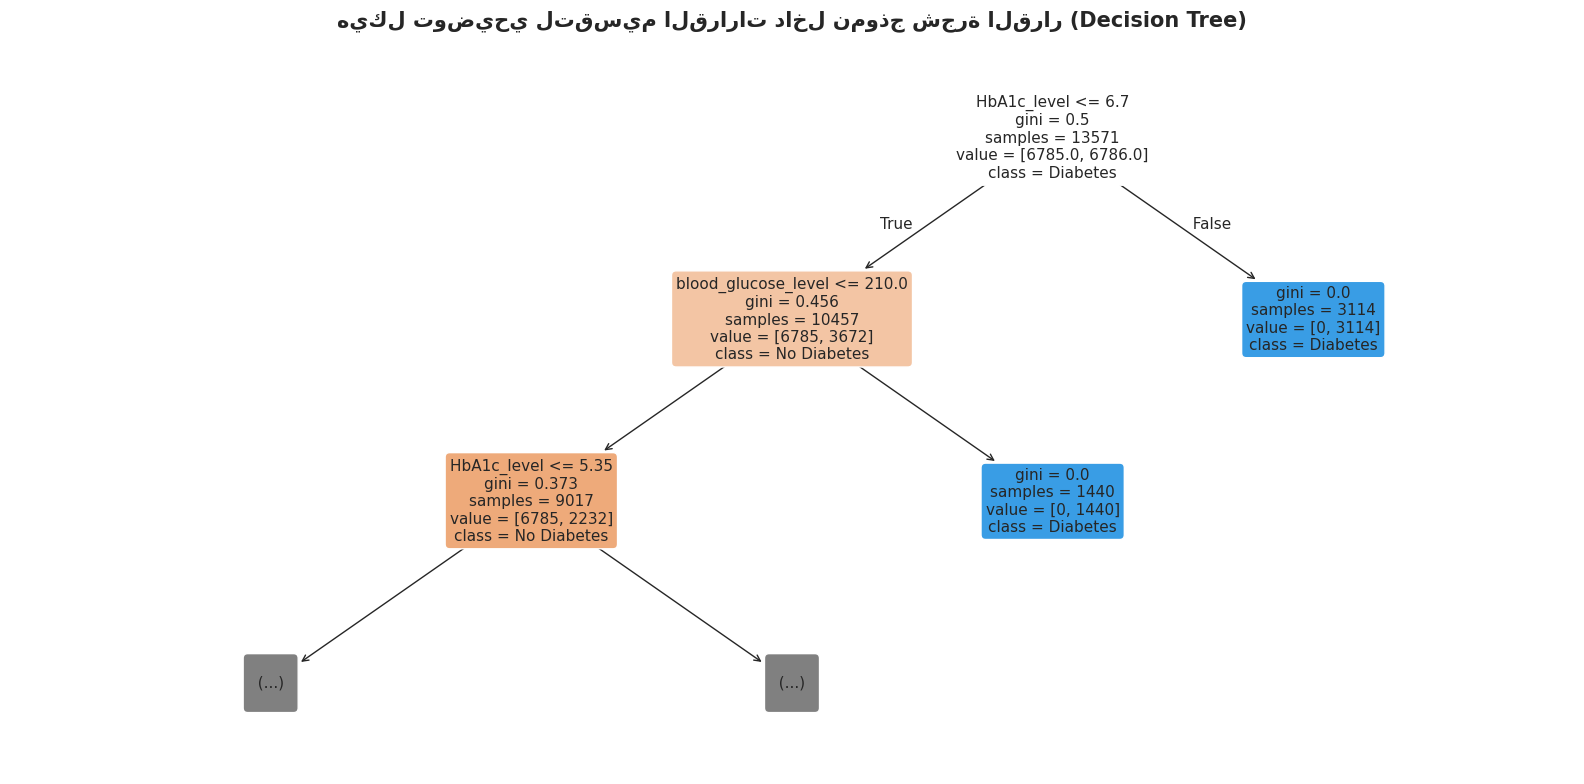

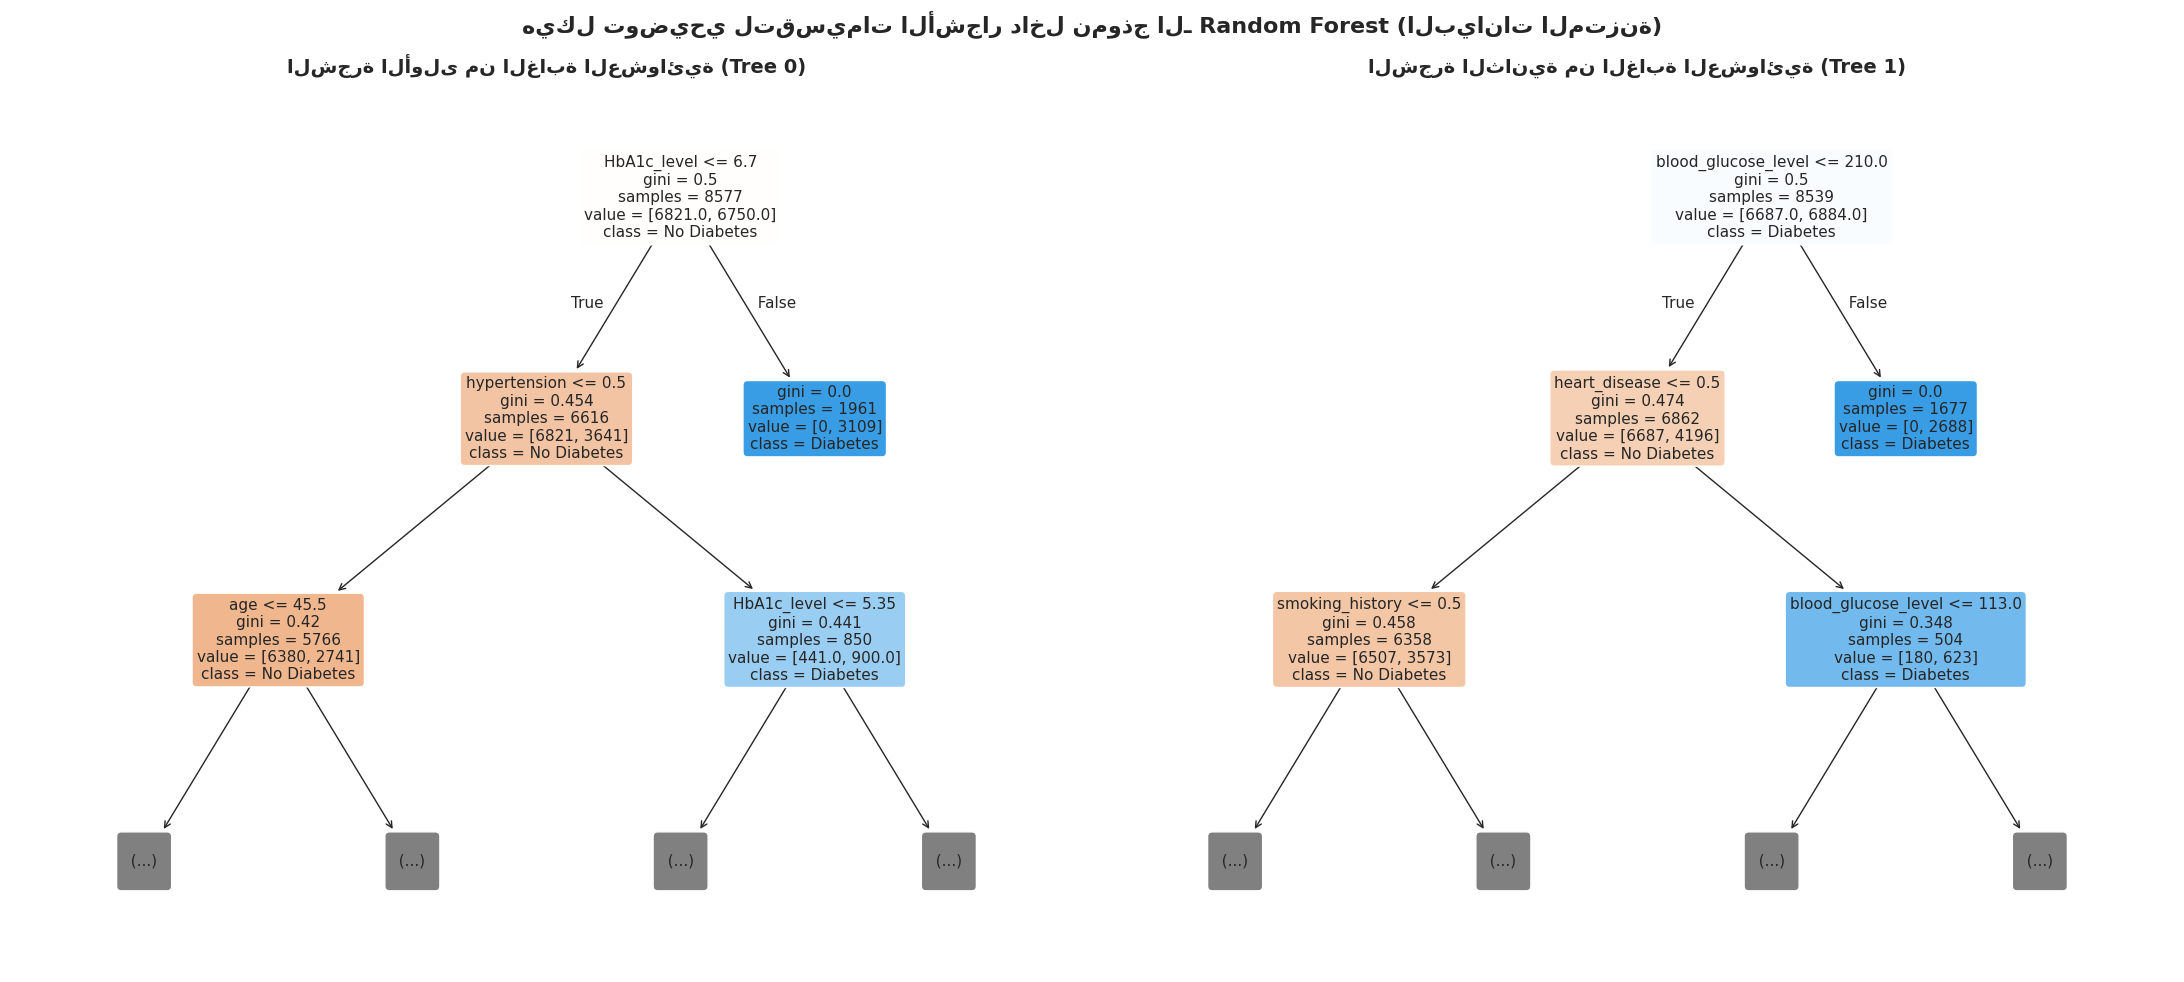

In [11]:
# 1. إعداد حساب غيت هاب (تأكد من تعديل الإيميل واسم المستخدم)
!git config --global user.email "saraaldenali5555@example.com"
!git config --global user.name "saraaldenali5555"

# 2. سحب المستودع باستخدام الـ Token (تأكد من وضع الرمز واسم المستودع الخاص بك)
!git clone https://colab@github.com/saraaldenali555/Machine_Learning_Training.git

# 3. الدخول إلى مجلد المستودع
%cd Machine_Learning_Training

# 4. نسخ ملف الكولاب الحالي إلى داخل مجلد المستودع (تأكد من تطابق اسم ملفك)
!cp /content/Training_Diabetes.ipynb .

# 5. تجهيز الملف وحفظه ورفعه تلقائياً
!git add .
!git commit -m "Update notebook from colab"
!git push origin main

Cloning into 'Machine_Learning_Training'...
fatal: could not read Password for 'https://colab@github.com': No such device or address
[Errno 2] No such file or directory: 'Machine_Learning_Training'
/content
cp: cannot stat '/content/Training_Diabetes.ipynb': No such file or directory
fatal: not a git repository (or any of the parent directories): .git
fatal: not a git repository (or any of the parent directories): .git
fatal: not a git repository (or any of the parent directories): .git
